In [91]:
import os

In [92]:
contracts_folder = '../data/raw_contracts/'

In [93]:
file_list = os.listdir(contracts_folder)
file_list

['Contract_02.pdf', 'Contract_03.pdf', 'Contract_01.pdf']

In [94]:
pip install PyPDF2


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [95]:
import PyPDF2

In [96]:
pdf_filename = file_list[0]
pdf_path = contracts_folder + pdf_filename

#Opening the pdf
with open(pdf_path,'rb') as file:
    pdf_reader = PyPDF2.PdfReader(file)

    num_pages = len(pdf_reader.pages)

    print(f"PDF:{pdf_filename}")
    print(f"Number of Pages: {num_pages}")

    for page_num in range(num_pages):
        page = pdf_reader.pages[page_num]
        text = page.extract_text()
        print(f"Page {page_num + 1}: {text[:100]}..")

PDF:Contract_02.pdf
Number of Pages: 22
Page 1:   
 
 
SOFTWARE LICENSE AND SUPPORT AGREEMENT  
 
This Software License and Support Agreement betwee..
Page 2:   
 
business rules definable in the Software rules engine.  
 
2. SCHEDULES  
 
The Schedules descr..
Page 3:   
 
4. LICENSE RESTRICTIONS  
 
a. Witho ut limiting the generality of the License granted in Secti..
Page 4:   
 
 
c. CityView shall supply all Updates and Upgrades  to Licensee at no additional charge other ..
Page 5:   
 
The parties agree that execution of the following agreements are conditions precedent to the ef..
Page 6:   
 
10. CITYVIEW’S PROPRIETARY RIGHTS  
 
The grant of the License herein contained permits the lim..
Page 7:   
 
12. WARRANTY OF INTELLECTUAL PROPERTY RIGHTS  
 
CityView warrants:  
a. that it has the full r..
Page 8:   
 
15. COUNTERPARTS  
 
This Agreement may be executed in counterparts (whether by facsimile or PD..
Page 9:   
 
IN WITNESS WHEREOF , Licensee and CityView have executed th

In [97]:
pip install pdfplumber


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [98]:
import pdfplumber

In [99]:
pdf_filename = file_list[0]
pdf_path = contracts_folder + pdf_filename

with pdfplumber.open(pdf_path) as pdf:
    first_page = pdf.pages[0]

    text = first_page.extract_text()

    print(f"PDF: {pdf_filename}")
    print(f"Total_pages: {len(pdf.pages)}")
    print("\n--- First Page Text --")
    print(text[:500])

PDF: Contract_02.pdf
Total_pages: 22

--- First Page Text --
SOFTWARE LICENSE AND SUPPORT AGREEMENT
This Software License and Support Agreement between CityView, an unincorporated division of N. Harris Computer
Corporation (“CityView”), and the City of Bend, Oregon (“Licensee”) is effective as of <Enter Effective Date>__ (the “Effective
Date”).
Whereas CityView and Licensee entered into a Contractual Services Agreement dated [enter date] for the provision of certain
professional services [in preparation of the license of certain CityView software to Licen


In [100]:
with pdfplumber.open(pdf_path) as pdf:
    first_page = pdf.pages[0]

    words = first_page.extract_words()

    print("First 10 words with positions (x0, top, x1, bottom):\n")

    for i, word in enumerate(words[:10]):
        print(f"{i+1}. '{word['text']}' - Top: {word['top']:.1f}, Bottom: {word['bottom']:.1f}")

First 10 words with positions (x0, top, x1, bottom):

1. 'SOFTWARE' - Top: 111.2, Bottom: 121.1
2. 'LICENSE' - Top: 111.2, Bottom: 121.1
3. 'AND' - Top: 111.2, Bottom: 121.1
4. 'SUPPORT' - Top: 111.2, Bottom: 121.1
5. 'AGREEMENT' - Top: 111.2, Bottom: 121.1
6. 'This' - Top: 140.3, Bottom: 149.3
7. 'Software' - Top: 140.3, Bottom: 149.3
8. 'License' - Top: 140.3, Bottom: 149.3
9. 'and' - Top: 140.3, Bottom: 149.3
10. 'Support' - Top: 140.3, Bottom: 149.3


In [41]:
HEADER_THRESHOLD = 100
FOOTER_THRESHOLD = 700

with pdfplumber.open(pdf_path) as pdf:
    for page_num, page in enumerate(pdf.pages):
        words = page.extract_words()
        filtered_words = [
            word for word in words
            if word['top'] > HEADER_THRESHOLD and word['top'] <FOOTER_THRESHOLD
        ]

        filtered_text = " ".join([ word['text'] for word in filtered_words ])

        print(f"\n=== Page {page_num + 1}===")
        print(filtered_text[:200])


=== Page 1===
SOFTWARE LICENSE AND SUPPORT AGREEMENT This Software License and Support Agreement between CityView, an unincorporated division of N. Harris Computer Corporation (“CityView”), and the City of Bend, Or

=== Page 2===
The Schedules described below and appended to this Agreement shall be deemed to be integral parts of this Agreement. Schedule “A” - Description of Software, Software & Maintenance Fees, Payment Milest

=== Page 3===
other than in connection with Licensee’s primary business or operations; (ii) disassemble, de-compile, reverse engineer, defeat license encryption mechanisms, or translate any part of the Software, (i

=== Page 4===
Services Agreement and professional services for the installation and implementation of the Upgrade that will be subject to CityView’s then-prevailing policies, terms and hourly rates. Licensee is sol

=== Page 5===
the Software; and b. the Contractual Services Agreement which shall detail CityView’s installation and implementation ser

In [101]:
import json
import os


In [102]:
os.makedirs("../data/processed/", exist_ok = True)

In [103]:
HEADER_THRESHOLD = 100
FOOTER_THRESHOLD = 700

for pdf_filename in file_list:
    pdf_path = contracts_folder + pdf_filename

    contract_id = pdf_filename.split('.')[0].lower()

    contract_data = {
        "contract_id": contract_id,
        "filename": pdf_filename,
        "total_pages": 0,
        "full_text": "",
        "pages":[]
    }

    with pdfplumber.open(pdf_path) as pdf:
        contract_data["total_pages"] = len(pdf.pages)

        for page_num, page in enumerate(pdf.pages):
            words = page.extract_words()
            filtered_words = [word for word in words if word['top'] > HEADER_THRESHOLD and word['top']<FOOTER_THRESHOLD]
            page_text = " ".join([ word['text'] for word in filtered_words])
            contract_data["pages"].append({
                "page_num": page_num +1,
                "text":page_text
            })

            contract_data["full_text"] += page_text
        
    output_path =f"../data/processed/{contract_id}.json"
    with open(output_path, 'w') as f:
        json.dump(contract_data, f, indent=2)
    
    print(f"Saved: {output_path}")

print("\n All Contract processed")



Saved: ../data/processed/contract_02.json
Saved: ../data/processed/contract_03.json
Saved: ../data/processed/contract_01.json

 All Contract processed


## Step 2 Chunking the Contracts

#### First Try: Regrex-based sentence splitting

In [104]:
import re

In [105]:
def chunk_by_sentences(text, target_chunk_size=1000, max_chunk_size=1200):
    sentences = re.split(r'(?<=\.)', text)

    chunks = []
    current_chunk = ""

    for sentence in sentences:
        if len(current_chunk + sentence) < max_chunk_size:
            current_chunk += sentence
        else:
            if current_chunk:
                chunks.append(current_chunk.strip())
            current_chunk = sentence

    if current_chunk:
        chunks.append(current_chunk.strip())

    return chunks

In [106]:
with open("../data/processed/contract_01.json","r") as f:
    contract = json.load(f)

test_chunks = chunk_by_sentences(contract["full_text"])

In [107]:
test_chunks

['This AGREEMENT is made by and between the County of Nevada, a political subdivision of the State of California (herein "County"), and <Contractor Name> (herein “Contractor”), wherein Contractor agrees to provide the software and services commonly known as <Name of Software System>. As described in the Schedules comprising this Agreement, Contractor will successfully implement <Name of Software System> consisting of all system modules and capabilities necessary to meet the County’s requirements as defined in the System Feature List presented in Appendix B-1. This AGREEMENT, including the following Schedules, constitutes the entire understanding and agreement between the Parties. This AGREEMENT may not be modified, supplemented or amended, in any manner, except by written agreement signed by both parties.',
 'Schedule A: General Terms and Conditions Schedule B: Software License Agreement Appendix B-1: System Feature List Schedule C: Software Maintenance Agreement Appendix C-1: Hosting 

In [108]:
import ssl
import certifi
import nltk

ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [109]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [110]:
def chunk_by_sentences_nltk(text, target_chunk_size=1000, max_chunk_size=1200):
    sentences = nltk.sent_tokenize(text)
    chunks = []
    current_chunk = ""

    for s in sentences :
        if len(current_chunk + s) < max_chunk_size:
            current_chunk += s
        else:
            if current_chunk:
                chunks.append(current_chunk.strip())
            current_chunk = s

    if current_chunk:
        chunks.append(current_chunk.strip())
    return chunks

In [111]:
with open('../data/processed/contract_01.json','r') as f:
    contract = json.load(f)

nltk_chunks = chunk_by_sentences_nltk(contract["full_text"])

In [112]:
nltk_chunks

['This AGREEMENT is made by and between the County of Nevada, a political subdivision of the State of California (herein "County"), and <Contractor Name> (herein “Contractor”), wherein Contractor agrees to provide the software and services commonly known as <Name of Software System>.As described in the Schedules comprising this Agreement, Contractor will successfully implement <Name of Software System> consisting of all system modules and capabilities necessary to meet the County’s requirements as defined in the System Feature List presented in Appendix B-1.This AGREEMENT, including the following Schedules, constitutes the entire understanding and agreement between the Parties.This AGREEMENT may not be modified, supplemented or amended, in any manner, except by written agreement signed by both parties.',
 'Schedule A: General Terms and Conditions Schedule B: Software License Agreement Appendix B-1: System Feature List Schedule C: Software Maintenance Agreement Appendix C-1: Hosting Ser

In [113]:
##Let's compare both and see

len(test_chunks)

99

In [114]:
len(nltk_chunks)

101

In [115]:
test_chunks[0][:200]

'This AGREEMENT is made by and between the County of Nevada, a political subdivision of the State of California (herein "County"), and <Contractor Name> (herein “Contractor”), wherein Contractor agrees'

In [116]:
nltk_chunks[0][:200]

'This AGREEMENT is made by and between the County of Nevada, a political subdivision of the State of California (herein "County"), and <Contractor Name> (herein “Contractor”), wherein Contractor agrees'

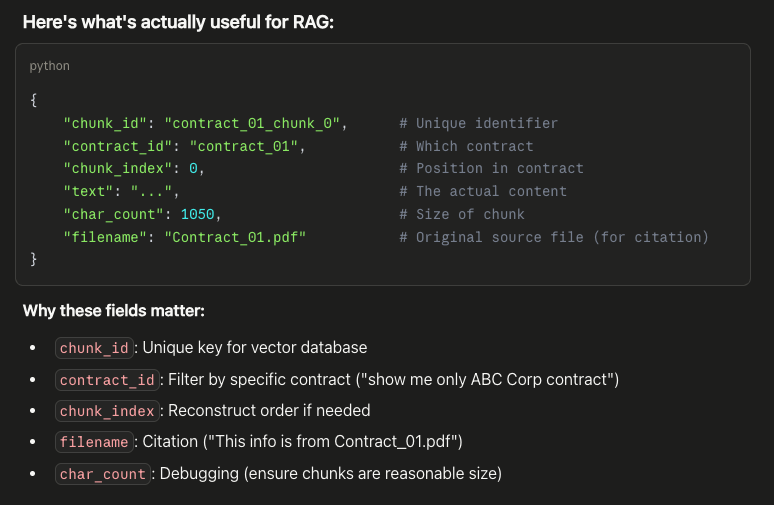

In [117]:
processed_folder = '../data/processed/'
contract_files = [ f for f in os.listdir(processed_folder) if f.endswith('.json') ]

In [118]:
all_chunks = []

for contract_file in contract_files:
    with open(processed_folder + contract_file, 'r') as f:
        contract = json.load(f)

    chunks = chunk_by_sentences_nltk(contract["full_text"])

    for idx, chunk_text in enumerate(chunks):
        chunk_data = {
            "chunk_id": f"{contract['contract_id']}_chunk_{idx+1}",
            "contract_id": contract["contract_id"],
            "chunk_index": idx+1,
            "text": chunk_text,
            "char_count": len(chunk_text),
            "file_name": contract["filename"]
        }

        all_chunks.append(chunk_data)
output_path = "../data/processed/all_chunks.json"
with open(output_path,'w') as f:
    json.dump(all_chunks, f,indent=2)

### Step 3 Text preprocessing and Embeddings

In [119]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/tarunvelvs/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [120]:
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

In [121]:
legal_imp_words = {'not','no','never','shall','must','may','will','without','nor'}
stop_words = set(stopwords.words("english")) - legal_imp_words
lemmatizer = WordNetLemmatizer()

In [122]:
len(stop_words)

194

In [123]:
def get_tag(tag):
    if tag.startswith("N"): return wordnet.NOUN
    elif tag.startswith("V"): return wordnet.VERB
    elif tag.startswith("R"): return wordnet.ADV
    elif tag.startswith("J"): return wordnet.ADJ
    else: return wordnet.NOUN


In [124]:
def preprocess_for_bm25(text):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]','', text)

    tokens = text.split()
    tokens = [ w for w in tokens if w not in stop_words ]

    tagged = pos_tag(tokens)

    results = [ lemmatizer.lemmatize(w, get_tag(tag)) for w, tag in tagged ]

    return ' '.join(results)



In [125]:
sample_text = "The client shall NOT receive 1,000 ADP credits in the US-EAST region."
preprocessed = preprocess_for_bm25(sample_text)

In [126]:
test_cases = [
    "The client shall NOT receive 1,000 ADP credits in the US-EAST region.",
    "This agreement is effective as of January 1st, 2024.",
    "The software will be running on production servers.",
]

for text in test_cases:
    print(preprocess_for_bm25(text))

client shall not receive 1000 adp credit useast region
agreement effective january 1st 2024
software will run production server


In [130]:
with open("../data/processed/all_chunks.json",'r') as f:
    all_chunks = json.load(f)

for chunk in all_chunks:
    chunk["text_preprocessed"] = preprocess_for_bm25(chunk["text"])

with open("../data/processed/all_chunks.json", 'w') as f:
    json.dump(all_chunks, f, indent=2)

#### Building BM25 Index

In [131]:
pip install rank-bm25


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [134]:
from rank_bm25 import BM25Okapi

with open("../data/processed/all_chunks.json",'r') as f:
    all_chunks = json.load(f)

corpus = [ s["text_preprocessed"].split() for s in all_chunks ]

bm25 = BM25Okapi(corpus)

In [138]:
##Testing with a sample query

test_query = "How many credits?"
query_preprocessed = preprocess_for_bm25(test_query)
query_tokens = query_preprocessed.split()

In [139]:
scores = bm25.get_scores(query_tokens)

In [140]:
scores

array([3.84498513, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 4.25811884, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 4.37399015, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [146]:
import numpy as np
top_25_indices = np.argsort(scores)[::-1][:25]

In [ ]:
#top_25_indices = np.sort(top_25_indices)

In [147]:
print(f"\n Query: {test_query}")
print(f"\n preprocessed Query: {query_preprocessed}")
print(f"]n Top 5 BM25 results")
for i, idx in enumerate(top_25_indices[:25]):
    print(f"\n{i+1} Score: {scores[idx]:.2f}")
    print(f" Chunk ID: {all_chunks[idx]['chunk_id']}")
    print(f" Text: {all_chunks[idx]['text'][:150]}")


 Query: How many credits?

 preprocessed Query: many credit
]n Top 5 BM25 results

1 Score: 4.37
 Chunk ID: contract_02_chunk_19
 Text: If no Successor Product(s) is/are available, then as Licensee’s exclusive remedy, CityView will work with Licensee to adjust Licensee’s going-forward 

2 Score: 4.26
 Chunk ID: contract_03_chunk_12
 Text: If LICENSEE breaches any of its obligations with respect to the use or confidentiality of the Software or Documentation, LICENSOR shall be entitled to

3 Score: 3.84
 Chunk ID: contract_03_chunk_1
 Text: 1.6: Example of a Data System Software License Agreement A data system software license agreement can be difficult to comprehend.This document intends

4 Score: 3.83
 Chunk ID: contract_02_chunk_53
 Text: This feature is available from the Home tab of the ribbon in CityView Desktop as well as in many of our add-on products.• CityView Connect Feedback (p

5 Score: 0.00
 Chunk ID: contract_01_chunk_4
 Text: 1.8 Confidential Information: Copyrights, Tra

In [148]:
pip install transformers torch


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### Embeddings

In [149]:
import transformers

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [150]:
from transformers import AutoTokenizer, AutoModel
import torch

In [151]:
tokenizer = AutoTokenizer.from_pretrained("nlpaueb/legal-bert-base-uncased")
model = AutoModel.from_pretrained("nlpaueb/legal-bert-base-uncased")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 29243.45it/s]
BertModel LOAD REPORT from: nlpaueb/legal-bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [152]:
def get_embedding(text):
    inputs = tokenizer(
        text,
        return_tensors = 'pt',
        padding =True,
        truncation = True,
        max_length = 512
    )

    #Pass through BERT
    with torch.no_grad():
        outputs = model(**inputs)

    cls_vector = outputs.last_hidden_state[:,0,:][0]

    return cls_vector.numpy()

In [153]:
from tqdm import tqdm

with open('../data/processed/all_chunks.json','r') as f:
    all_chunks = json.load(f)

embeddings = []

for chunk in tqdm(all_chunks):
    embedding = get_embedding(chunk["text"])
    embeddings.append(embedding)

#Convert to numpy array
embeddings = np.array(embeddings)

np.save("../data/processed/embeddings.npy", embeddings)


100%|██████████| 187/187 [00:18<00:00, 10.01it/s]


In [154]:
import chromadb

In [155]:
from chromadb.config import Settings

In [156]:
client = chromadb.PersistentClient(path="../database/chroma_db")

collection = client.get_or_create_collection(
    name="Contract_chunks",
    metadata = {"description":"Contract chunks with Legal- BERT embeddings"}
)

In [157]:
with open("../data/processed/all_chunks.json","r") as f:
    all_chunks = json.load(f)

embeddings = np.load("../data/processed/embeddings.npy")

array([[-0.03375405, -0.06489199, -0.14287002, ..., -0.18276569,
         0.24116239,  0.03511009],
       [ 0.42302814,  0.4991872 ,  0.01418591, ..., -0.09136129,
         0.69850147,  0.34280926],
       [ 0.6209374 ,  0.58232373, -0.27592236, ..., -0.14320807,
         0.6671138 ,  0.42845345],
       ...,
       [ 0.02848415, -0.05005597, -0.00827614, ...,  0.25999177,
         0.07117303,  0.19014877],
       [-0.13088098,  0.36628824, -0.26379162, ...,  0.17500515,
         0.14000775,  0.6024378 ],
       [-0.17128064, -0.09779537, -0.08019564, ..., -0.22651072,
         0.32613805, -0.00893002]], shape=(187, 768), dtype=float32)

In [161]:
ids = []
documents = []
metadatas = []
embeddings_list = []

for i, chunk in enumerate(all_chunks):
    ids.append(chunk["chunk_id"])
    documents.append(chunk["text"])
    embeddings_list.append(embeddings[i].tolist())
    
    metadatas.append({
        "contract_id": chunk["contract_id"],
        "chunk_index": chunk["chunk_index"],
        "filename": chunk["file_name"],
        "char_count": chunk["char_count"]
    })

# Check lengths BEFORE adding to Chroma
print(f"ids length: {len(ids)}")
print(f"documents length: {len(documents)}")
print(f"metadatas length: {len(metadatas)}")
print(f"embeddings_list length: {len(embeddings_list)}")

ids length: 187
documents length: 187
metadatas length: 187
embeddings_list length: 187


In [162]:
print(f"Collection count BEFORE adding: {collection.count()}")

# Try to peek at existing data
try:
    existing = collection.get(limit=5)
    print(f"Existing IDs: {existing['ids'][:5]}")
except:
    print("No existing data")

Collection count BEFORE adding: 0
Existing IDs: []


In [165]:
ids = []
documents = []
metadatas = []
embeddings_list = []

for i, chunk in enumerate(all_chunks):
    ids.append(chunk["chunk_id"])
    documents.append(chunk["text"])
    embeddings_list.append(embeddings[i].tolist())
    metadatas.append({
        "contract_id": chunk["contract_id"],
        "chunk_index": chunk["chunk_index"],
        "filename": chunk["file_name"],
        "char_count": chunk["char_count"]
    })

collection.add(
    ids=ids,
    embeddings=embeddings_list,
    documents=documents,
    metadatas=metadatas
)


In [172]:
# Generate query embedding
query = "How many ADP credits does the client receive?"
query_embedding = get_embedding(query)

print(f"Query embedding shape: {query_embedding.shape}")

# Query Chroma with the embedding
test_results = collection.query(
    query_embeddings=[query_embedding.tolist()],  # Pass embedding directly
    n_results=5
)

print("\n--- Top 5 Chroma Results (Embedding Similarity) ---\n")
for i, (doc, metadata, distance) in enumerate(zip(
    test_results['documents'][0], 
    test_results['metadatas'][0],
    test_results['distances'][0]
)):
    print(f"{i+1}. Distance: {distance:.4f}")
    print(f"   Chunk Index: {metadata['chunk_index']}")
    print(f"   Contract: {metadata['contract_id']}")
    print(f"   Text: {doc[:150]}...\n")

Query embedding shape: (768,)

--- Top 5 Chroma Results (Embedding Similarity) ---

1. Distance: 34.2700
   Chunk Index: 28
   Contract: contract_02
   Text: Licensee further acknowledges that it is solely responsible for determining whether the Functional Requirements meet the operational needs of Licensee...

2. Distance: 59.7172
   Chunk Index: 29
   Contract: contract_03
   Text: Some technologies such as high-level encryption may not be exported, and license agreements may reflect the limitation....

3. Distance: 87.2611
   Chunk Index: 24
   Contract: contract_01
   Text: Upon receipt of such notice, County will provide Contractor in writing a notice that Contractor has until the effective date of termination, change in...

4. Distance: 92.5583
   Chunk Index: 55
   Contract: contract_01
   Text: County shall keep appropriate records of the number and location of all copes and make such records available to Contractor upon request.All copies th...

5. Distance: 93.1568
   Chunk I

#### Hybrid Retrieval - BM25 + Embedding Reranking

In [173]:
from numpy.linalg import norm

In [175]:
def cosine_similarity(vec1, vec2):
    return np.dot(vec1, vec2)/(norm(vec1) * norm(vec2))

In [178]:
def hybrid_retrieval(query, top_k_bm25=25, top_k_final=5):

    query_preprocessed = preprocess_for_bm25(query)
    query_tokens = query_preprocessed.split()
    bm25_scores = bm25.get_scores(query_tokens)
    top_bm25_indices = np.argsort(bm25_scores)[::-1][:top_k_bm25]

    query_embedding = get_embedding(query)

    candidate_scores = []

    for idx in top_bm25_indices:
        candidate_embedding = embeddings[idx]
        similarity = cosine_similarity(query_embedding,candidate_embedding)
        candidate_scores.append({
            'chunk_index':idx,
            'chunk_id': all_chunks[idx]['chunk_id'],
            'similarity':similarity,
            'bm25_score': bm25_scores[idx],
            'chunk_data': all_chunks[idx]
        })

    candidate_scores.sort(key=lambda x: -x["similarity"])

    top_results = candidate_scores[:top_k_final]

    return top_results

In [179]:
query = "Describe the Software License Agreement?"
results = hybrid_retrieval(query, top_k_bm25=25, top_k_final=5)

In [180]:
results

[{'chunk_index': np.int64(88),
  'chunk_id': 'contract_01_chunk_3',
  'similarity': np.float32(0.6680498),
  'bm25_score': np.float64(5.102174538675532),
  'chunk_data': {'chunk_id': 'contract_01_chunk_3',
   'contract_id': 'contract_01',
   'chunk_index': 3,
   'text': '1.2 Acceptance Certificate: A certificate provided by the Contractor that is signed by the County confirming the Acceptance of each phase as defined within the Project Management Plan.1.3 Acceptance Plan: That document, delivered as a component of the Implementation Plan document, which defines and describes the acceptance tests and conditions which define Acceptance.1.4 Agreement: This Agreement, all schedules, appendices and exhibits thereto, and any and all subsequent duly executed amendments thereto.1.5 Authorized Representative: The person or persons authorized by County to work with Contractor to implement changes to the Software, submit Software issues to Contractor to resolve, and authorize the Contractor to ma

## LLM Integration

In [181]:
pip install ollama


[notice] A new release of pip available: 22.3 -> 26.0.1
[notice] To update, run: pip3.11 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import ollama

def generate_answer_llm(query, retrieved_chunks):
    context = ""
    for i, chunk 
